# Recruit test: does the *real* update recruit the subcomponents our map recruits, and is the set about what was learned?

Results in `experiments/recruit_test/results/recruit.json` (per-subcomponent gate changes in `results/large/*_dg.pt`). Scoring and every number: `reports/2026-10-19_analysis_recruit-test.md`. Plan and design check: `reports/2026-10-19_plan_recruit-test.md`. Predictions were filed before the run: `experiments/recruit_test/results/predictions.json`. One RunPod 4090, $0.26, 106 s.

## What we were trying to test

**The project's question.** Can a small post-training update be commuted past a VPD decomposition, and if not, is that because post-training *creates* new mechanisms or because it *recruits* existing ones? `GOALS.md` lists the routes an update can take: through the changed subcomponents directly ("strengthen"), through the frozen causal-importance function Γ switching on subcomponents that already exist ("reveal"), or outside the subcomponents altogether ("create").

**What we knew.** The concentration test (2026-10-15, amendment 2) found that when the *pull-back* (our map: train the subcomponents' U and V on the fine-tune loss with Γ and Δ fixed) learns the emoticon → `o` behaviour, and its weight change is then put into Δ with the subcomponents left alone, the frozen Γ switches on the same 135 to 250 pre-existing subcomponents at the trigger whichever pull-back arm produced the change (Jaccard 0.59 to 0.88). That set carries about half of the behaviour. This was the evidence for "reveal". But every set in that comparison came from our own map, and nothing showed the set was about `o` rather than about *any* perturbation at the trigger position.

**The two questions here.**
1. Does the **real** update (a full-weight fine-tune, a LoRA) make Γ recruit the same set as the pull-back did?
2. Is the set **target-specific**: does a fine-tune to a *different* token at the same trigger, with the same recipe and update size, recruit a different set?

**The trick: do-nothing placement.** Every arm's weight change δW is added to the target model and left in Δ; the released subcomponents are not touched. The only thing that can change in the CI-masked model (subcomponents gated by Γ, Δ out) is *which subcomponents Γ gates on*, because Γ reads the new activations. So the measurement isolates re-gating.

**Arms** (emoticon task, 73 held-out windows, trigger at index 20):
- `ft_s0`, `ft_s1`: the full-weight fine-tune, round 1's recipe, 10 steps, two optimiser seeds (their overlap is the noise floor);
- `lora_r8`: a normal rank-8 LoRA on `h.2.mlp.down_proj` (the paper's site), scored at step 10. This is the LoRA's own δW placed do-nothing; it is **not** "LoRA through the pull-back" (training the subcomponents with the LoRA's support and rank), which has never been run;
- `null_a`, `null_b`: the same emoticon windows, the same `:` trigger position, the same recipe and step count, but the loss asks for a *different token* at the trigger instead of `o` (null_b: ` http`). This rules out the competing explanation for any overlap between the arms above: that any update which perturbs the activations at the `:` position makes frozen Γ switch on the same subcomponents, whatever was learned. A random δW cannot play this role because it is inert (P5); a fine-tune to another target is a perturbation of the same size at the same position that does change behaviour. Not run: predicting `o` after other triggers, or the same δW applied at other positions, which would ask different questions;
- `random_dw`: a Gaussian δW with the fine-tune's per-matrix norms (expected inert; shows the obvious null has no power);
- `pullback_adam`: the pull-back's δW placed the same way, i.e. amendment 2's reference arm reproduced.

**Measurements.** Per arm: *r*, the re-gating share, the fraction of the held-out trigger log-odds gain that the W₀ subcomponents reproduce under the new gate pattern (`local_faith.route_split`; here the direct and interaction shares are zero by construction and the residual share is one); *S_on*, the alive subcomponents whose mean gate at the trigger rises by more than 0.3; *recovery*, the share of the re-gating effect obtained when only S_on takes the new gates. Across arms: the Jaccard overlap of S_on.

**Pre-registered predictions** (thresholds in `predictions.json`): P0 target-specific (J with nulls ≤ floor − 0.3), P1 real fine-tune recruits the map's set (J ≥ 0.5), P2 r ≥ 0.3, P3 LoRA r ≥ 0.3 and J ≥ 0.4, P4 recovery ≥ 0.4 with random control < 0.1, P5 random δW inert; R1/R2 on whether the set is the model's natural `o` machinery (conditional on enough Pile positions). All predicted to pass except R2.

In [1]:
import json, math
from pathlib import Path
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt

R = Path('../experiments/recruit_test/results')
res = json.loads((R / 'recruit.json').read_text())
pred = json.loads((R / 'predictions.json').read_text())
A, S = res['arms'], res['score']
alive = torch.load('../experiments/transport_test/results/large/alive.pt', weights_only=False)['alive']
dg = {a: torch.load(R / 'large' / f'{a}_dg.pt', weights_only=False)['dg'] for a in A}

ARMS = ['ft_s0', 'ft_s1', 'lora_r8', 'pullback_adam', 'null_a', 'null_b', 'random_dw']
LABEL = {'ft_s0': 'fine-tune, seed 0', 'ft_s1': 'fine-tune, seed 1', 'lora_r8': 'LoRA r8 (layer-2 site)',
         'pullback_adam': 'pull-back (our map)', 'null_a': 'null: other target <|endoftext|>', 'null_b': 'null: other target " http"',
         'random_dw': 'random δW, matched norm'}
# colour follows the entity: blue = real fine-tune, orange = LoRA, aqua = our map, yellow = different-target nulls, grey = inert null
COL = {'ft_s0': '#2a78d6', 'ft_s1': '#6da7ec', 'lora_r8': '#eb6834', 'pullback_adam': '#1baf7a', 'null_a': '#eda100', 'null_b': '#c98500',
       'random_dw': '#9a9892'}
TXT, MUTED = '#0b0b0b', '#52514e'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#b5b3ad',
                     'axes.labelcolor': TXT, 'xtick.color': MUTED, 'ytick.color': MUTED, 'axes.titleweight': 'bold', 'font.size': 10})

def flat(v):  # alive subcomponents only, all 24 matrices concatenated, fixed key order
    return torch.cat([v[k][alive[k].cpu().bool()] for k in sorted(v)]).numpy()
print({a: {'gain': round(A[a]['routes']['gain'], 2), 'r': round(A[a]['routes']['shares']['r'], 3), 'n_on': A[a]['n_on']['0.3']} for a in ARMS})

{'ft_s0': {'gain': 13.5, 'r': 0.596, 'n_on': 202}, 'ft_s1': {'gain': 13.57, 'r': 0.611, 'n_on': 209}, 'lora_r8': {'gain': 16.92, 'r': 0.54, 'n_on': 237}, 'pullback_adam': {'gain': 11.6, 'r': 0.508, 'n_on': 135}, 'null_a': {'gain': 17.73, 'r': 0.545, 'n_on': 117}, 'null_b': {'gain': 12.99, 'r': 0.599, 'n_on': 132}, 'random_dw': {'gain': -0.01, 'r': 1.185, 'n_on': 0}}


## Could it do it? Re-gating the W₀ subcomponents alone reproduces most of the trigger effect

Each bar is *r* for one arm: how much of the fine-tuned model's held-out log-odds gain for its target token is reproduced by the **unchanged** W₀ subcomponents when Γ reads the fine-tuned activations. The subcomponents did not move; only the gates did. Dashed lines are the pre-registered pass (0.3) and null (0.15) thresholds of P2. The random-δW arm has no gain (−0.02 nats), so its r is undefined and it is shown as empty.

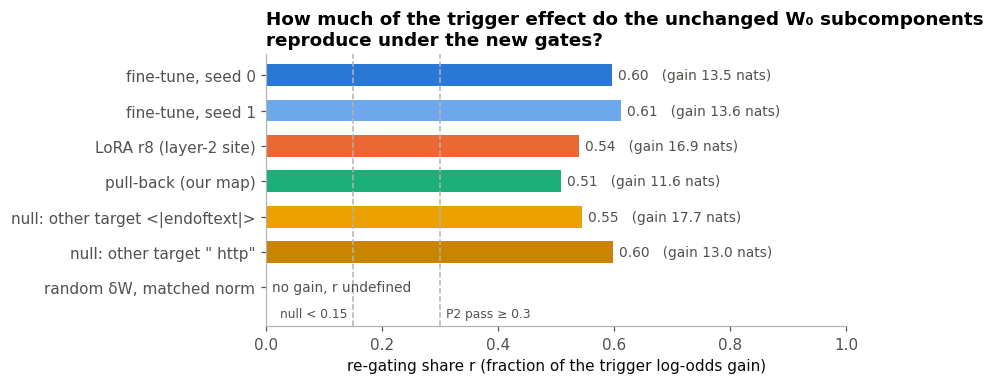

In [2]:
fig, ax = plt.subplots(figsize=(8, 3.6))
arms = [a for a in ARMS if a != 'random_dw']
vals = [A[a]['routes']['shares']['r'] for a in arms]
y = np.arange(len(arms))[::-1]
ax.barh(y, vals, color=[COL[a] for a in arms], height=0.62)
for yi, a, v in zip(y, arms, vals):
    ax.text(v + 0.01, yi, f"{v:.2f}   (gain {A[a]['routes']['gain']:.1f} nats)", va='center', color=MUTED, fontsize=9)
ax.barh([-1], [0], color=COL['random_dw']); ax.text(0.01, -1, 'no gain, r undefined', va='center', color=MUTED, fontsize=9)
ax.set_yticks(list(y) + [-1]); ax.set_yticklabels([LABEL[a] for a in arms] + [LABEL['random_dw']])
for t, s, ha in ((0.3, 'P2 pass ≥ 0.3', 'left'), (0.15, 'null < 0.15', 'right')):
    ax.axvline(t, ls='--', lw=1, color='#b5b3ad'); ax.text(t + (0.01 if ha == 'left' else -0.01), -1.75, s, color=MUTED, fontsize=8, ha=ha, va='center')
ax.set_ylim(-2.1, len(arms) - 0.4); ax.set_xlim(0, 1); ax.set_xlabel('re-gating share r (fraction of the trigger log-odds gain)')
ax.set_title('How much of the trigger effect do the unchanged W₀ subcomponents\nreproduce under the new gates?', loc='left')
plt.tight_layout(); plt.show()

- **Yes, more than half.** For the real fine-tune r is 0.60 (both seeds), for the LoRA 0.54, for the pull-back reference 0.51. P2 and the r half of P3 pass as filed. With the subcomponents frozen at W₀, just letting Γ switch on different ones recovers the majority of a 13 to 17 nat gain.
- **But r is not about `o`.** The two different-target nulls read 0.55 and 0.60, the same as the `o` arms. So r measures how much *any* trigger-local behaviour of this size can be routed through the existing subcomponents by re-gating. It does not say which behaviour. The question "is it the same mechanism?" has to be answered by *which* subcomponents switch on, below.
- **A norm-matched random δW does nothing** (P5): it neither changes the behaviour nor moves a single gate past 0.3. That is why the different-target fine-tune, not a random direction, is the null in this test.

## Which subcomponents switch on, and is it the same set? (the main result)

Jaccard overlap of the switched-on sets (S_on at threshold 0.3) between every pair of arms. Darker is more overlap. The diagonal is 1 by definition; the number to compare everything against is the **seed-to-seed floor**, the overlap between the two fine-tune seeds, which is as close to "the same set" as this measurement can get.

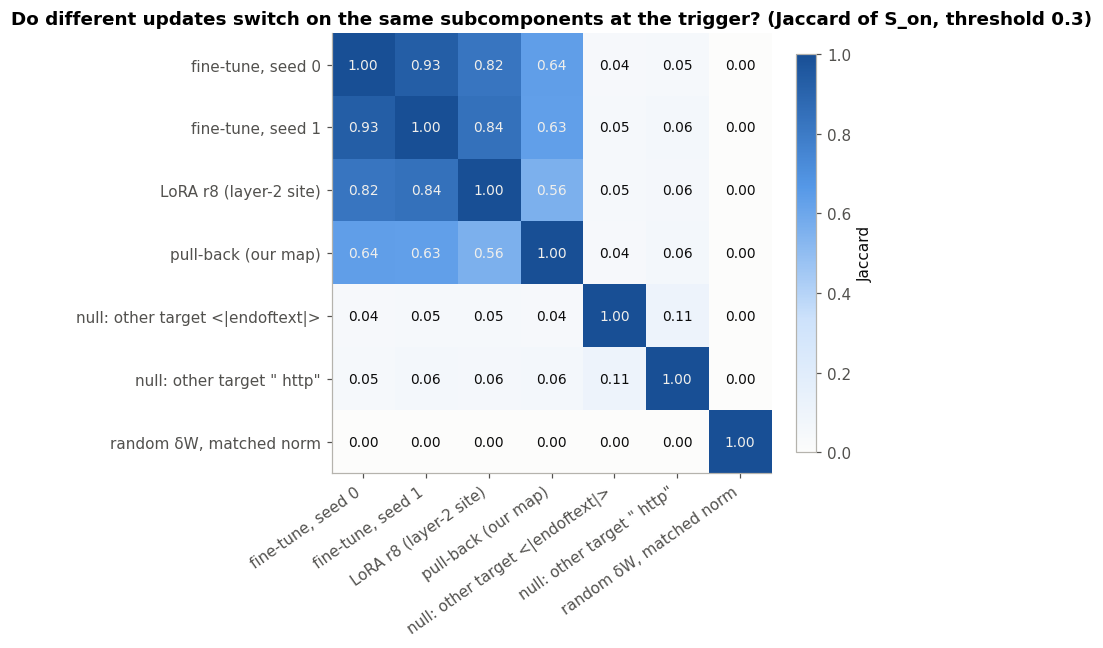

sizes of S_on at 0.3: {'fine-tune, seed 0': 202, 'fine-tune, seed 1': 209, 'LoRA r8 (layer-2 site)': 237, 'pull-back (our map)': 135, 'null: other target <|endoftext|>': 117, 'null: other target " http"': 132, 'random δW, matched norm': 0}
share of the pull-back set inside the fine-tune set: 0.97
share of the fine-tune set inside the LoRA set: 0.98


In [3]:
J = res['jaccard']['0.3']
def jac(a, b):
    return 1.0 if a == b else J.get(f'{a}|{b}', J.get(f'{b}|{a}', float('nan')))
M = np.array([[jac(a, b) for b in ARMS] for a in ARMS])
fig, ax = plt.subplots(figsize=(7.2, 6))
im = ax.imshow(M, cmap=plt.matplotlib.colors.LinearSegmentedColormap.from_list('blue', ['#fcfcfb', '#cde2fb', '#5598e7', '#184f95']), vmin=0, vmax=1)
ax.set_xticks(range(len(ARMS))); ax.set_yticks(range(len(ARMS)))
ax.set_xticklabels([LABEL[a] for a in ARMS], rotation=35, ha='right'); ax.set_yticklabels([LABEL[a] for a in ARMS])
for i in range(len(ARMS)):
    for j in range(len(ARMS)):
        v = M[i, j]; ax.text(j, i, '–' if np.isnan(v) else f'{v:.2f}', ha='center', va='center', fontsize=9, color='#f0efec' if v > 0.55 else TXT)
ax.set_title('Do different updates switch on the same subcomponents at the trigger? (Jaccard of S_on, threshold 0.3)')
plt.colorbar(im, ax=ax, fraction=0.04, label='Jaccard'); plt.tight_layout(); plt.show()
print('sizes of S_on at 0.3:', {LABEL[a]: A[a]['n_on']['0.3'] for a in ARMS})
from commute import recruit as R
mem = {a: R.members(R.switched(dg[a], 0.3)) for a in ARMS}
print('share of the pull-back set inside the fine-tune set:', round(len(mem['pullback_adam'] & mem['ft_s0']) / len(mem['pullback_adam']), 3))
print('share of the fine-tune set inside the LoRA set:', round(len(mem['ft_s0'] & mem['lora_r8']) / len(mem['ft_s0']), 3))

- **Floor: 0.93.** Two seeds of the same fine-tune switch on almost exactly the same ~200 subcomponents. The set is a property of the update, not of optimiser noise (G0 passes, so the set-based predictions are scorable).
- **The real fine-tune recruits the map's set: 0.64 (P1 passes, rule ≥ 0.5).** The pull-back arm's set is smaller (135 vs 202) and 97% of it lies inside the fine-tune's set, so the 0.64 is set-size, not disagreement: the real update recruits everything the map recruited, plus more.
- **The LoRA recruits the fine-tune's set: 0.82 (P3 passes).** A rank-8 edit of one matrix and a full-weight update of all 24 switch on nearly the same subcomponents.
- **A different target at the same trigger recruits a disjoint set: 0.04 to 0.06 (P0 passes, rule ≤ 0.63).** The nulls' sets are not smaller perturbations: their n_on (117, 132) and relative update norm (0.0102, 0.0105) are at or below the fine-tune's (202, 0.0113). The two nulls also barely overlap each other (0.11), so each target has its own set. This is the strong kind of pass.
- The ordering is the same at thresholds 0.1 and 0.5 (`res['jaccard']`), so it is not an artefact of where the cut sits.

## The same picture subcomponent by subcomponent

Each point is one alive subcomponent (about 9 900). The axes are its mean gate change at the trigger, Δg, under two different updates. If two updates recruit the same mechanism the points lie on the diagonal; if they recruit different ones the points spread along the axes. Left: fine-tune against LoRA. Right: fine-tune against the different-target null. The grey lines are the 0.3 threshold that defines S_on.

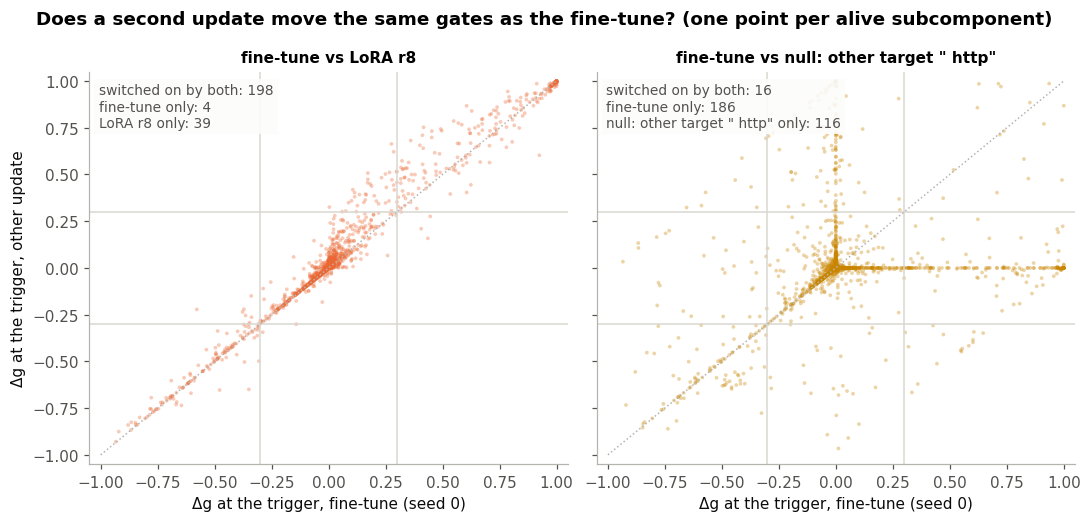

In [4]:
x = flat(dg['ft_s0'])
fig, axes = plt.subplots(1, 2, figsize=(10, 4.8), sharex=True, sharey=True)
for ax, other, col, name in ((axes[0], 'lora_r8', COL['lora_r8'], 'LoRA r8'), (axes[1], 'null_b', COL['null_b'], 'null: other target " http"')):
    yv = flat(dg[other])
    ax.scatter(x, yv, s=6, alpha=0.35, color=col, edgecolors='none')
    for t in (0.3, -0.3):
        ax.axhline(t, color='#d9d7d1', lw=1); ax.axvline(t, color='#d9d7d1', lw=1)
    ax.plot([-1, 1], [-1, 1], color='#b5b3ad', lw=1, ls=':')
    both = int(((x > 0.3) & (yv > 0.3)).sum()); only_x = int(((x > 0.3) & (yv <= 0.3)).sum()); only_y = int(((x <= 0.3) & (yv > 0.3)).sum())
    ax.text(0.02, 0.97, f'switched on by both: {both}\nfine-tune only: {only_x}\n{name} only: {only_y}', transform=ax.transAxes, va='top', fontsize=9, color=MUTED,
            bbox=dict(facecolor='#fcfcfb', edgecolor='none', alpha=0.9, pad=3))
    ax.set_xlabel('Δg at the trigger, fine-tune (seed 0)'); ax.set_title(f'fine-tune vs {name}', fontsize=10)
axes[0].set_ylabel('Δg at the trigger, other update'); axes[0].set_xlim(-1.05, 1.05); axes[0].set_ylim(-1.05, 1.05)
fig.suptitle('Does a second update move the same gates as the fine-tune? (one point per alive subcomponent)', fontweight='bold')
plt.tight_layout(); plt.show()

- **Left:** the LoRA's gate changes track the fine-tune's along the diagonal, including the switched-*off* quadrant (both negative). Same mechanism, found by a one-matrix edit.
- **Right:** the null's gate changes form a cross: subcomponents the fine-tune switches on are untouched by the null and vice versa. Almost nothing is switched on by both. A fine-tune to a different word at the same position re-routes through a different set of existing subcomponents.
- This figure compares gate changes only. It says the two updates move the same gates, not that those gates produce the behaviour (see the recovery section below).

## Does the switched-on set carry the re-gating effect?

Recovery: give only S_on the new gates and keep W₀'s gates everywhere else; what fraction of the re-gating effect (the move from W₀'s gates to the state's gates, with the W₀ subcomponents) comes back? The hollow markers are the control: a random set of alive subcomponents of the same size per matrix. The dashed line is P4's pre-registered pass threshold.

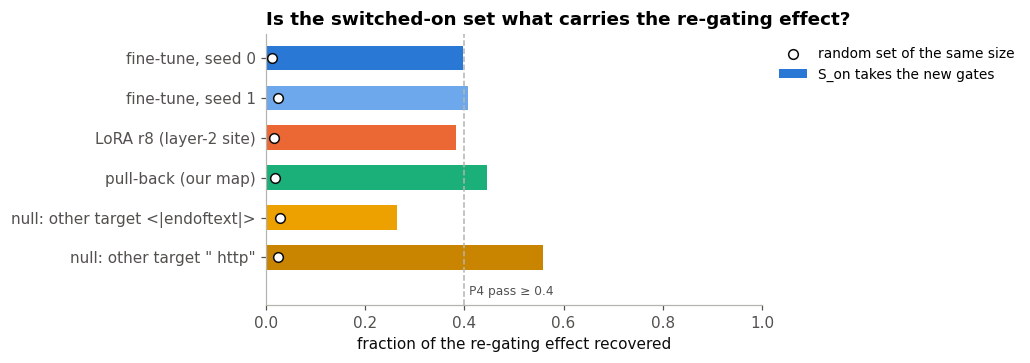

ft_s0 recovery 0.3977 random 0.0109


In [5]:
arms = [a for a in ARMS if a != 'random_dw']
fig, ax = plt.subplots(figsize=(9.5, 3.4))
y = np.arange(len(arms))[::-1]
ax.barh(y, [A[a]['recovery'] for a in arms], color=[COL[a] for a in arms], height=0.62, label='S_on takes the new gates')
ax.scatter([A[a]['recovery_random_control'] for a in arms], y, facecolors='white', edgecolors=TXT, s=40, zorder=3, label='random set of the same size')
ax.axvline(0.4, ls='--', lw=1, color='#b5b3ad'); ax.text(0.41, -0.85, 'P4 pass ≥ 0.4', ha='left', va='center', color=MUTED, fontsize=8)
ax.set_ylim(-1.2, len(arms) - 0.4); ax.set_yticks(y); ax.set_yticklabels([LABEL[a] for a in arms]); ax.set_xlim(0, 1)
ax.set_xlabel('fraction of the re-gating effect recovered'); ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1.0), frameon=False, fontsize=9)
ax.set_title('Is the switched-on set what carries the re-gating effect?', loc='left')
plt.tight_layout(); plt.show()
print('ft_s0 recovery', round(A['ft_s0']['recovery'], 4), 'random', round(A['ft_s0']['recovery_random_control'], 4))

- **No. The switched-on set carries 40% of the re-gating effect, and P4 fails.** We predicted it would carry most of it. The random control (1%) shows the 40% is real, but 60% of the effect is not in the ~200 subcomponents that switched on.
- We do not know where the other 60% is. It could be in the ~100 further subcomponents whose gates moved by less than 0.3, in the ~130 that switched *off*, or in interactions between them. None of that was measured.
- So the overlap results above compare *which gates moved*. They do not show that those gates are what produces the behaviour: most of the effect lies outside the set we are comparing.

## Does it match the predictions?

Every pre-registered item with its rule, what we predicted, what we observed, and the outcome. Gates (G) are checks on the measurement; predictions (P, R) are claims.

In [6]:
rows = [
 ('G0 seed floor', 'J(ft_s0, ft_s1) ≥ 0.5', 'ok', f"{S['G0_seed_floor']['J']:.3f}", 'ok'),
 ('G3 identities', 'd = i = 0, e_Δ = 1 for every arm with gain ≥ 1 nat', 'ok', 'all arms', 'ok'),
 ('G4 reproduces amendment 2', 'pull-back n_on within 20 of 135, gap within 0.3 of 5.89', 'ok', f"n_on {S['G4_reproduces_amendment_2']['n_on_0.3']}, gap {S['G4_reproduces_amendment_2']['gap']:.3f}", 'ok, exact'),
 ('G5 LoRA locality', 'layer ≤ 2 gates unmoved by a layer-2 LoRA', 'ok', f"max |Δg| in layers ≤ 2 = {S['G5_lora_locality']['max_dg_layer_le2']:.2f}", 'FAIL: premise wrong (Γ is global)'),
 ('G6 arms learn', 'P(target) ≥ 0.9 (nulls ≥ 0.5)', 'ok', 'all ≥ 0.998', 'ok'),
 ('P0 target-specific', 'J(ft, null) ≤ floor − 0.3 for both nulls', 'pass', f"{S['P0_target_specific']['J_null_a']:.3f}, {S['P0_target_specific']['J_null_b']:.3f} (floor {S['P0_target_specific']['floor']:.2f})", 'PASS'),
 ('P1 real update recruits the map’s set', 'J(ft_s0, pull-back) ≥ 0.5', 'pass', f"{S['P1_real_update_recruits_the_maps_set']['J']:.3f}", 'PASS'),
 ('P2 re-gating share', 'r(ft_s0) ≥ 0.3', 'pass (≈ 0.5)', f"{S['P2_regating_share_of_the_real_update']['r']:.3f}", 'PASS'),
 ('P3 LoRA re-gates', 'r ≥ 0.3 and J(layers ≥ 3) ≥ 0.4', 'pass', f"r {S['P3_lora_regates_downstream']['r']:.3f}, J {S['P3_lora_regates_downstream']['J_ge3']:.3f}", 'PASS'),
 ('P4 set carries re-gating', 'recovery ≥ 0.4, random < 0.1', 'pass', f"{S['P4_set_carries_the_regating']['recovery']:.3f}, random {S['P4_set_carries_the_regating']['random']:.3f}", 'FAIL by 0.002'),
 ('P5 random δW inert', 'gain < 1 nat and n_on < 10', 'pass', f"gain {S['P5_random_dw_is_inert']['gain']:.3f}, n_on {S['P5_random_dw_is_inert']['n_on_0.3']}", 'PASS'),
 ('R1 set is natural `o` machinery (above chance)', 'conditional on ≥ 200 Pile positions before `o`', 'pass', f"{res['natural_o']['n_positions_before_o']} positions in {res['natural_o']['n_rows']} rows", 'NOT RUN'),
 ('R2 natural-`o` overlap is target-specific', 'same condition', 'null', '', 'NOT RUN'),
]
df = pd.DataFrame(rows, columns=['item', 'rule', 'predicted', 'observed', 'outcome'])
pd.set_option('display.max_colwidth', 70); df

,item,rule,predicted,observed,outcome
0,G0 seed floor,"J(ft_s0, ft_s1) ≥ 0.5",ok,0.930,ok
1,G3 identities,"d = i = 0, e_Δ = 1 for every arm with gain ≥ 1 nat",ok,all arms,ok
2,G4 reproduces amendment 2,"pull-back n_on within 20 of 135, gap within 0.3 of 5.89",ok,"n_on 135, gap 5.897","ok, exact"
3,G5 LoRA locality,layer ≤ 2 gates unmoved by a layer-2 LoRA,ok,max |Δg| in layers ≤ 2 = 1.00,FAIL: premise wrong (Γ is global)
4,G6 arms learn,P(target) ≥ 0.9 (nulls ≥ 0.5),ok,all ≥ 0.998,ok
5,P0 target-specific,"J(ft, null) ≤ floor − 0.3 for both nulls",pass,"0.042, 0.050 (floor 0.93)",PASS
6,P1 real update recruits the map’s set,"J(ft_s0, pull-back) ≥ 0.5",pass,0.636,PASS
7,P2 re-gating share,r(ft_s0) ≥ 0.3,pass (≈ 0.5),0.596,PASS
8,P3 LoRA re-gates,r ≥ 0.3 and J(layers ≥ 3) ≥ 0.4,pass,"r 0.540, J 0.857",PASS
9,P4 set carries re-gating,"recovery ≥ 0.4, random < 0.1",pass,"0.398, random 0.011",FAIL by 0.002


- **Five of six scored claims pass as predicted. P4 fails: the switched-on set carries 40% of the re-gating effect, not most of it. R1/R2 did not run.** The measurement gates all pass except G5, whose premise was wrong (next section).
- Two things to carry into any reading: the LoRA checkpoint (step 10) was fixed before the run and turned out to also be the one closest to the fine-tune in log-odds; the null_a target was chosen by a buggy rule (it fell back to token 0, `<|endoftext|>`, because no plain token sat above P(`o`) at the trigger). null_a is still a different-target fine-tune that learned, and its numbers match null_b's, but it is not the token the filed rule describes. The rule has been replaced for future runs.

## Surprise: Γ is global, so a layer-2 edit moves layer-0 gates

The gate G5 assumed that Γ computes each matrix's gates from that matrix's own input, so a LoRA on `h.2.mlp.down_proj` could only re-gate layer 3. The data said otherwise, and reading the pinned `param-decomp` confirmed why: the released Γ (`GlobalSharedTransformerCiFn`) rms-norms and concatenates the inputs of **all 24 matrices** at each position, projects, runs **bidirectional** transformer blocks over positions, and splits the output into per-matrix gates. Every gate depends on every matrix's input at every position in the window. The chart shows where each arm's switched-on subcomponents sit by layer.

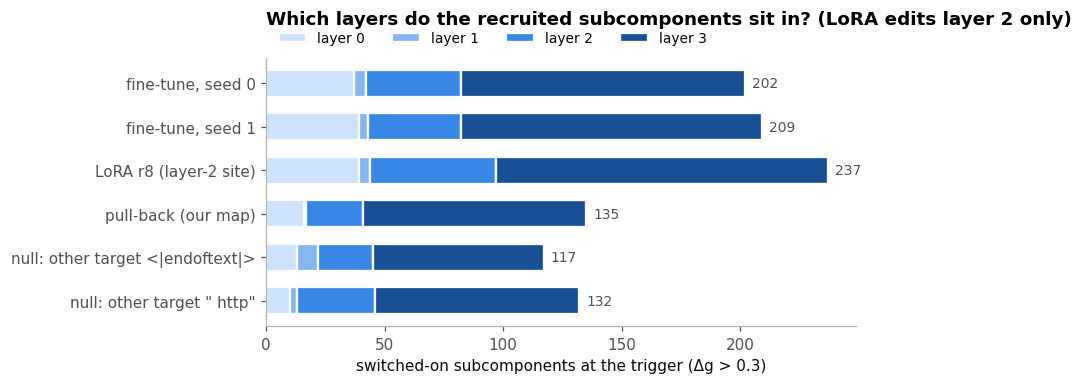

In [7]:
arms = [a for a in ARMS if a != 'random_dw']
layers = ['0', '1', '2', '3']
LC = ['#cde2fb', '#86b6ef', '#3987e5', '#184f95']
fig, ax = plt.subplots(figsize=(8, 3.6))
y = np.arange(len(arms))[::-1]; left = np.zeros(len(arms))
for lay, c in zip(layers, LC):
    v = np.array([A[a]['by_layer_on']['0.3'].get(lay, 0) for a in arms])
    ax.barh(y, v, left=left, color=c, height=0.62, edgecolor='#fcfcfb', linewidth=1.5, label=f'layer {lay}')
    left += v
for yi, tot in zip(y, left):
    ax.text(tot + 3, yi, f'{int(tot)}', va='center', color=MUTED, fontsize=9)
ax.set_yticks(y); ax.set_yticklabels([LABEL[a] for a in arms]); ax.set_xlabel('switched-on subcomponents at the trigger (Δg > 0.3)')
ax.legend(frameon=False, fontsize=9, ncol=4, loc='lower left', bbox_to_anchor=(0.0, 1.0)); ax.set_title('Which layers do the recruited subcomponents sit in? (LoRA edits layer 2 only)', loc='left', pad=22)
plt.tight_layout(); plt.show()

- Under the LoRA, 39 layer-0 and 5 layer-1 subcomponents switch on, although no layer-0 or layer-1 weight changed and their matrix inputs are identical. Γ saw the change through its global input. The whole-set Jaccard with the fine-tune is 0.82 and the layers-3-only version 0.86, so P3 holds either way; the restriction was just unnecessary.
- **Consequence for the whole project.** Every "trigger-local" gate measurement (here, in the concentration test, in the running task ladder) reads a gate at the trigger that is computed from the *whole window*. "Re-gating at the trigger" therefore includes re-gating driven by changed activations at other positions. The task ladder's G1b argument still holds (that matrix's output feeds no decomposed matrix, so Γ's inputs do not change at all). The "blind to" lines should be re-worded; this is a backlog item.
- Layer 3 holds 60 to 70% of every set, and the two seeds agree layer by layer. The fine-tune's and LoRA's sets are larger than the pull-back's in every layer, which is the main reason the pull-back overlap is 0.64 rather than 0.9.

## Re-gating builds up over LoRA training

r for the LoRA at every saved checkpoint, with the fine-tune's step-10 value for reference. The LoRA reaches the fine-tune's held-out P(`o`) by step 10 and keeps training to step 100 with falling off-target KL.

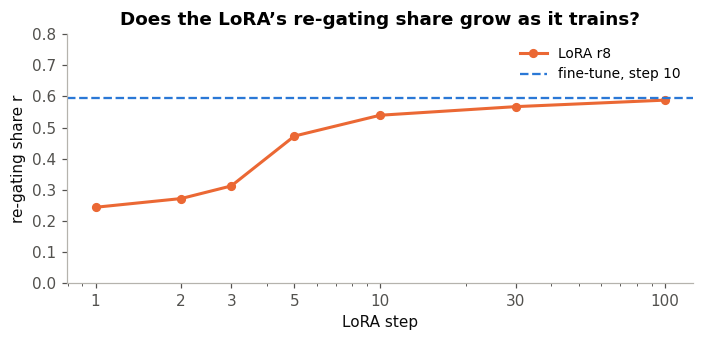

{1: 0.0131, 2: 0.0215, 3: 0.055, 5: 0.5186, 10: 0.9994, 30: 0.9997, 100: 0.9963}


In [8]:
lc = res['lora_checkpoints']; steps = sorted(int(s) for s in lc)
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.plot(steps, [lc[str(s)]['r'] for s in steps], marker='o', ms=5, lw=2, color=COL['lora_r8'], label='LoRA r8')
ax.axhline(A['ft_s0']['routes']['shares']['r'], color=COL['ft_s0'], lw=1.5, ls='--', label='fine-tune, step 10')
ax.set_xscale('log'); ax.set_xticks(steps); ax.set_xticklabels(steps); ax.set_ylim(0, 0.8)
ax.set_xlabel('LoRA step'); ax.set_ylabel('re-gating share r'); ax.legend(frameon=False, fontsize=9)
ax.set_title('Does the LoRA’s re-gating share grow as it trains?')
plt.tight_layout(); plt.show()
print({s: round(lc[str(s)]['p_o'], 4) for s in steps})

- r rises from 0.24 at step 1 to 0.54 at step 10 and 0.59 at step 100, approaching the full-weight fine-tune's 0.60. A converged LoRA routes about as much through existing gates as the full fine-tune does. Nothing here suggests that longer training pushes the behaviour *out* of the existing subcomponents; if anything the opposite, within 100 steps.

## What we learned

1. **The real update moves the same gates as our map.** The full-weight fine-tune and a one-matrix LoRA switch on the same ~200 pre-existing subcomponents that the pull-back switched on (overlap 0.64 and 0.82 against a floor of 0.93). Re-gating with the W₀ subcomponents reproduces 60% of the behaviour change, but the ~200 switched-on subcomponents account for only 40% of that re-gating effect. Where the rest comes from is not known.
2. **The set of moved gates depends on *what* was learned.** A fine-tune of the same size to a different token at the same trigger moves a nearly disjoint set (0.04). The re-gating *share*, by contrast, is the same for every target (0.55 to 0.60): r says how routable a trigger-local behaviour is, not which one it is.
3. **The obvious null has no power.** A norm-matched random δW changes nothing. Any future gate-based claim needs a *learned* null.
4. **Γ is global.** Gates at any position depend on every matrix's input at every position. This changes how every trigger-local gate measurement in the project should be described, and it means "which layer did the edit touch" has no bearing on "which gates can move".
5. **The pull-back is a slightly conservative version of the real update** in this respect: smaller set, smaller r, mostly a subset of the fine-tune's set.

## How compelling is the evidence?

**Strong points.**
- Pre-registered thresholds, a measured seed-to-seed floor (0.93), and a null with power (the different-target fine-tune) at *matched* update size and set size. The effect sizes are large relative to the floor and to each other: 0.64 / 0.82 against 0.04 is not a threshold artefact, and the same ordering holds at cuts of 0.1 and 0.5.
- The reference arm reproduces the earlier experiment exactly (n_on 135, gap 5.897 vs 5.893), so the two experiments are on the same footing.
- The per-subcomponent scatter shows the result without any summary statistic.
- The route-split identities (d = i = 0, e_Δ = 1) hold to numerical precision, so the measurement is doing what it says.

**Weak points, in order of how much they worry me.**
- **One task, one behaviour the model already has, 10 steps, 73 held-out windows.** Emoticon → `o` is the most favourable case for "recruit": the paper found one subcomponent for it. Whether a behaviour the model lacks is also routed through existing gates is exactly what the task ladder (running) is for. Nothing here speaks to "create".
- **The switched-on set carries only 40% of the re-gating effect (P4 failed).** "The same set" in this notebook means "the same gate shift", measured through frozen Γ's gates, which are a *prediction* of causal importance. Most of the effect lies outside the set being compared, and the switched-off set is unexamined.
- **r equals 0.6 for the nulls too.** Re-gating carries a majority of *any* trigger-local behaviour of this size, so r on its own cannot distinguish reveal from a generic property of frozen Γ with a global receptive field. Only the set does.
- **We do not know what the recruited subcomponents did before.** Whether they are the model's existing `o` machinery (R1/R2) was not testable with 256 Pile rows. Until that is shown, "recruit" means "re-use existing subcomponents in the new context", not "re-use the existing `o` mechanism".
- **Two blemishes:** P4 missed its threshold by 0.002, and null_a was mis-selected by a bug (still a valid null; its numbers match null_b's).

**Overall:** strong evidence that, for this task, the real fine-tune, a LoRA and the pull-back move the same target-specific set of gates, and that re-gating alone reproduces most of the behaviour change. Weak evidence that the switched-on set is itself the mechanism (it carries 40% of the re-gating effect), weak evidence about what those subcomponents *are*, and none about tasks the model lacks.

## What we might look at next

In rough order of value per dollar:

1. **What did the recruited subcomponents do at W₀?** Re-run the natural-`o` comparison with about 600 Pile rows (200+ positions before `o`), or define "natural" by the model's own P(`o`) rather than by the next token. If S_on overlaps the natural `o` machinery, "recruit" is the strong claim. If not, the fine-tune is borrowing subcomponents for a new job, which is closer to "repurpose" and bears on the create/recruit definition in `backlog.md`.
2. **The switched-off set** (about 130 per arm). Is it also target-specific? Does switching it off carry the other 60% of the re-gating effect that S_on does not?
3. **Across the ladder's tasks.** The running task ladder gives r per task for the real fine-tune; saving its gate shifts would give S_on per task for free, and the Jaccard between tasks of different rungs would show whether a behaviour the model lacks still recruits (large, target-specific set) or not (small set, low r, large e_gate).
4. **Pin down "recruit" vs "create" in these terms** (backlog, 2026-10-19). This test suggests a working definition: recruit = large target-specific S_on with high recovery and r; create = low r with the behaviour in e_gate or Δ. That mapping should be written down before the ladder's routes are scored.
5. **LoRA through the pull-back.** Still never run (backlog, 2026-10-15: arms (i) same matrix and (ii) same rank, both on `h.2.mlp.down_proj`, defined through `/design` and waiting on the task-local harness, which now exists). This notebook only placed a *normal* LoRA do-nothing. Whether the pull-back can learn the LoRA's update with the LoRA's support and rank, and whether it then moves the same gates, is open.
6. **Smaller things:** seeds for the nulls; LoRA on all 24 matrices; the fine-tune's set at steps 1, 3 and 30 (does the set form early and stay?); the same measurement with Γ allowed to move, which is the first thing frozen-Γ results cannot speak to.

**Not run in this round:** everything in the list above; see the "Not run" list in `reports/2026-10-19_analysis_recruit-test.md`.